# Session 4 — Why Models Must Hallucinate

**Series:** *Chasing "I Don't Know" in Modern Language Models*

**Session length:** ~55 min.
**Compute:** CPU sufficient; GPU optional (and noticeably more comfortable for Part 4).
**Prerequisite:** Sessions 0–3. In particular `generate_with_topk_trace` (Session 1) and `sequence_logprob` (Session 3).

## Framing

By now you have watched a model pick tokens one at a time (Session 1), seen what machinery produces those picks (Session 2), and measured the gap between what a model *says* and what it *knows* (Session 3).

This session answers the question those three raise: **why does that gap exist at all, and why can't it simply be engineered away?**

The short version, in three independent parts:

1. **It is structurally unavoidable.** There are formal results saying that for any model of this kind, on some inputs, fabrication is not a bug you can patch out.
2. **Calibration itself forces it.** A model that is well-calibrated on its training distribution *must* assign probability to content it has essentially never seen — and content it has essentially never seen is where it invents.
3. **Training actively pays for it.** Under the grading rules used almost everywhere in evaluation and preference data, guessing scores better than abstaining. The incentive is not accidental; it is arithmetic.

And then one mechanism that turns a single bad token into a paragraph of confident fiction: **snowballing**. That last part is where you will run this workshop's first *causal intervention* — you will reach into the generation, change one token, and watch the whole answer change with it.

---

In [1]:
import os
import re
import numpy as np
import torch
import matplotlib.pyplot as plt

from workshop_utils import (
    load_model_and_tokenizer,
    pick_device,
    pick_dtype,
    set_all_seeds,
    generate_with_topk_trace,
    sample_completions,
    sequence_logprob,
)

os.makedirs("figures", exist_ok=True)

device = pick_device()
dtype = pick_dtype(device)

set_all_seeds(0)
tokenizer, model = load_model_and_tokenizer(
    "Qwen/Qwen2.5-1.5B-Instruct",
    device=device,
    dtype=dtype,
)

# Parts 2 and 3 are pure arithmetic and run instantly. Part 1 and Part 4 call
# the model; lower these if you are on CPU and impatient.
N_SAMPLES = 8

Loading Qwen/Qwen2.5-1.5B-Instruct @ main onto cuda as torch.bfloat16...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  loaded: 28 layers, hidden 1536, vocab 151936


## Part 1 — What is, and is not, a hallucination

"Hallucination" is used loosely in public discussion to mean *"the model said something I didn't like."* The literature is narrower, and the distinction matters because the two standard kinds have different causes and different fixes.

**Intrinsic hallucination** — the output contradicts the *source material provided in the prompt*. You gave the model a document; it reported something the document does not say. This is a failure of grounding, and it is the failure mode that matters most in retrieval-augmented pipelines, summarization, and "chat with your PDF" products.

**Extrinsic hallucination** — the output is not contradicted by the prompt, but is false *in the world*. Invented citations, invented dates, invented people. This is a failure of knowledge, and no amount of prompt discipline removes it, because the prompt was never the problem.

**What is *not* a hallucination** (worth being pedantic about, because conflating these makes any measurement meaningless):

| Behavior | Why it isn't hallucination |
|---|---|
| *"I don't know."* | Abstention. The correct response to unknowability — and the one this workshop is about. |
| *"I think it's around 1890, but I'm not certain."* | Hedging. An assertion with its confidence marked. May still be wrong, but it is not a fabrication presented as fact. |
| *"I can't help with that request."* | Safety refusal. Shaped by an entirely different part of post-training; counting it as abstention contaminates the measurement (Session 6 keeps them in separate columns). |
| A claim that was true at training time and is now stale | Staleness. The model reported its world correctly; the world moved. |
| Fiction the user explicitly asked for | Compliance. |
| Register drift, verbosity, sycophantic tone | Style. Session 5's territory, not this one's. |

Let's produce one of each hallucination kind, under identical decoding settings.

### 1a. Intrinsic: contradicting the provided text

The passage below is fictional and deliberately *counter-prior*: it reports a fish population **increasing**, where the overwhelming pattern in the training corpus is that fish populations decline. If the model answers from its prior rather than from the text in front of it, that is an intrinsic hallucination — and we can count how often it happens.

In [2]:
PASSAGE = (
    "In a 2019 survey, the Baltic Marine Institute reported that cod stocks in the "
    "Gotland Basin rose by 12% between 2005 and 2015, reversing the trend of the "
    "previous decade. The authors attributed the increase to a temporary reduction "
    "in trawling pressure following a licensing dispute."
)
INTRINSIC_PROMPT = (
    PASSAGE
    + "\n\nAccording to the passage above, what happened to cod stocks in the "
      "Gotland Basin between 2005 and 2015? Answer in one sentence."
)

set_all_seeds(0)
intrinsic_samples = sample_completions(
    model, tokenizer, INTRINSIC_PROMPT,
    n=N_SAMPLES, temperature=0.7, max_new_tokens=60, apply_chat_template=True,
)

UP = re.compile(r"\b(rose|increas\w*|grew|growth|recover\w*|up by|higher)\b", re.I)
DOWN = re.compile(r"\b(fell|declin\w*|decreas\w*|dropped|collaps\w*|lower|shrank)\b", re.I)

faithful = contradicted = ambiguous = 0
for i, s in enumerate(intrinsic_samples):
    up, down = bool(UP.search(s)), bool(DOWN.search(s))
    verdict = "faithful" if (up and not down) else ("CONTRADICTS" if (down and not up) else "ambiguous")
    faithful += verdict == "faithful"
    contradicted += verdict == "CONTRADICTS"
    ambiguous += verdict == "ambiguous"
    print(f"[{verdict:>11}] {' '.join(s.split())[:130]}")

print(f"\nfaithful to the passage: {faithful}/{N_SAMPLES}   "
      f"contradicting it: {contradicted}/{N_SAMPLES}   ambiguous: {ambiguous}/{N_SAMPLES}")

[   faithful] Cod stocks in the Gotland Basin rose by 12% between 2005 and 2015 after a temporary reduction in trawling pressure following a lic
[   faithful] Cod stocks in the Gotland Basin rose by 12% between 2005 and 2015 due to a temporary reduction in trawling pressure following a li
[  ambiguous] Cod stocks in the Gotland Basin rose by 12% from 2005 to 2015 due to a temporary decrease in trawling pressure after a licensing d
[  ambiguous] Cod stocks in the Gotland Basin increased by 12% between 2005 and 2015 due to a temporary decrease in trawling pressure after a li
[  ambiguous] Cod stocks in the Gotland Basin rose by 12% between 2005 and 2015 due to a temporary decrease in trawling pressure after a licensi
[   faithful] Cod stocks in the Gotland Basin rose by 12% between 2005 and 2015 due to a temporary reduction in trawling pressure after a licens
[  ambiguous] Cod stocks in the Gotland Basin increased by 12% from 2005 to 2015, reversing a decline seen earlier in the decade.


On a well-behaved 1.5B model this prompt is usually answered faithfully — the passage is short, recent in context, and unambiguous. Intrinsic hallucination becomes common when the source is *long* (the relevant sentence competes with thousands of other tokens for attention), when the source is *counter-prior* (as here), and when the question requires combining several sentences.

If your run shows zero contradictions, that is a real result, not a broken demo. Exercise 1 asks you to make the demo fail on purpose: bury the passage in filler text, or make the claim even more counter-prior, and find the point where the model starts answering from its prior instead of from the page.

### 1b. Extrinsic: inventing a world

No source material now — just a question about something that does not exist.

In [3]:
EXTRINSIC_PROMPT = (
    "Who wrote the 1987 novel 'The Salt Meridian', and what is it about? "
    "Answer in two sentences."
)

set_all_seeds(0)
extrinsic_samples = sample_completions(
    model, tokenizer, EXTRINSIC_PROMPT,
    n=5, temperature=0.7, max_new_tokens=80, apply_chat_template=True,
)

for i, s in enumerate(extrinsic_samples):
    print(f"--- sample {i} ---\n{' '.join(s.split())[:260]}\n")

--- sample 0 ---
The 1987 novel "The Salt Meridian" was written by Mo Yan, a Chinese novelist known for his realistic and socially critical works. It tells the story of an elderly fisherman who uses salt as currency to help his community rebuild after a disaster.

--- sample 1 ---
"The Salt Meridian" was written by Yu Hsien-yüan (also known as Yu Han-chun), and it tells the story of an elderly woman named Mei who navigates through her final days while dealing with various challenges related to salt trade along the Silk Road during the M

--- sample 2 ---
"The Salt Meridian" was written by Jia Pingwa and tells the story of a young man's journey along the Silk Road to find his father.

--- sample 3 ---
The 1987 novel "The Salt Meridian" was written by Mo Yan, a renowned Chinese author. The book tells the story of a young man who travels along the salt trade routes to become a merchant and experiences the harsh realities of life on the frontier during China's

--- sample 4 ---
The 1987 no

Read those five samples as a set, not individually. Each one, on its own, is fluent, specific and plausible: a named author, a genre, a plot. Together they are mutually incompatible — different authors, different plots, different decades of setting. Nothing in the *style* of any single answer distinguishes it from the model's answer about a real novel.

This is Session 1's resampling diagnostic doing exactly what it did there, on a case where the mechanism is now named. And it points at the honest limit you already know: inconsistency across samples reveals fabrication, but **consistency does not reveal truth** — that is the blind spot Session 8 measures directly.

---

## Part 2 — Three reasons this cannot be engineered away

It is tempting to read the above as an engineering shortfall: a bigger model, cleaner data, better prompting. The research of the last few years says otherwise, for three separate and independent reasons. They are *different arguments* — they are often mashed together in blog posts, and attaching each to the right source matters if you plan to cite them.

### 2a. The computability argument — Xu et al. (2024), *"Hallucination is Inevitable"*

The argument, in plain language: define hallucination as any mismatch between the model's output and a ground-truth function. Then, in a formalized setting where the model is a computable function and the ground truth ranges over a suitably rich set of functions, you can construct — by diagonalization, the same move as in the halting problem — an input on which any given model must be wrong. No amount of training data or parameters removes the constructed counterexample, because the construction is defined *relative to the model*.

**How much to load onto this.** It is a real theorem about a formal setting, and it is the right citation for "there is a structural floor, not just an engineering gap." It is **not** a statement about how often GPT-class models fabricate citations in practice, and the idealization (arbitrary computable ground truth, worst-case inputs) is strong. Cite it for the existence of a floor, not for its height. The related informal move — invoking the Entscheidungsproblem or Rice's theorem directly as though it settled the matter — is an intuition pump, not a proof, and a reviewer will say so.

### 2b. The calibration argument — Kalai & Vempala (2024), *"Calibrated Language Models Must Hallucinate"*

This is the sharper and, for our purposes, the more useful result, because it is *quantitative* and because its mechanism is something you can compute yourself in ten lines.

The shape of the argument: consider facts that carry no learnable regularity — arbitrary, one-off facts of the kind "person X was born in city Y". A model that is **calibrated** on its training distribution must assign, to the space of such statements, roughly as much probability as that space actually carries. But a large share of one-off facts appear in the training corpus *exactly once*. By a Good–Turing argument, the singleton rate estimates the mass of facts that exist but were **never** seen. The model has to spend that mass somewhere — and since it cannot know which specific unseen facts are the true ones, a calibrated model necessarily emits plausible-shaped false statements at a rate bounded below by (roughly) the singleton rate.

The uncomfortable corollary: **a model that never hallucinates on that class of facts is, on that class, not calibrated.** Truthfulness and calibration trade off against each other. You can have a model that abstains constantly — but it gets there by being *miscalibrated in the safe direction*, which is a design choice, not a free lunch.

Let's watch the arithmetic that drives it.

In [4]:
def zipf_corpus_stats(vocab_size=5_000_000, corpus_sizes=(10_000, 30_000, 100_000,
                                                          300_000, 1_000_000, 3_000_000),
                      exponent=1.0, seed=0):
    """Sample 'facts' from a Zipf-shaped world and count how many appear once.

    Each draw is one mention of one fact in a training corpus. The Good-Turing
    missing-mass estimate is N1/N: the number of facts seen exactly once,
    divided by the number of mentions. It estimates the probability that the
    *next* fact you encounter is one you have never seen before.
    """
    rng = np.random.default_rng(seed)
    ranks = np.arange(1, vocab_size + 1)
    p = ranks.astype(float) ** (-exponent)
    p /= p.sum()

    rows = []
    for n in corpus_sizes:
        draws = rng.choice(vocab_size, size=n, p=p)
        counts = np.bincount(draws, minlength=vocab_size)
        seen = counts[counts > 0]
        n1 = int((counts == 1).sum())
        rows.append({
            "corpus_size": n,
            "distinct_facts_seen": int(seen.size),
            "singletons": n1,
            "singleton_share_of_types": n1 / max(seen.size, 1),
            "missing_mass": n1 / n,          # Good-Turing
        })
    return rows


stats = zipf_corpus_stats()
print(f"{'mentions':>10} {'distinct':>10} {'seen once':>10} "
      f"{'% of types':>11} {'missing mass':>13}")
for r in stats:
    print(f"{r['corpus_size']:>10,} {r['distinct_facts_seen']:>10,} {r['singletons']:>10,} "
          f"{100*r['singleton_share_of_types']:>10.1f}% {100*r['missing_mass']:>12.2f}%")

  mentions   distinct  seen once  % of types  missing mass
    10,000      5,909      5,316       90.0%        53.16%
    30,000     15,645     13,701       87.6%        45.67%
   100,000     44,277     38,046       85.9%        38.05%
   300,000    112,968     94,346       83.5%        31.45%
 1,000,000    300,939    238,512       79.3%        23.85%
 3,000,000    697,175    513,381       73.6%        17.11%


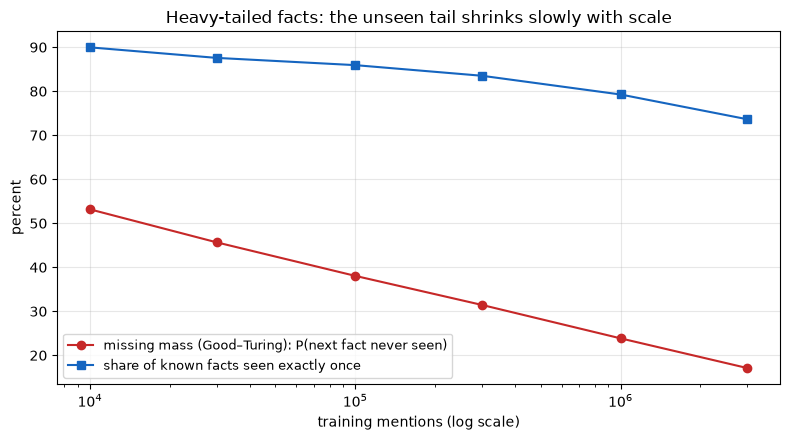

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
xs = [r["corpus_size"] for r in stats]
ax.plot(xs, [100 * r["missing_mass"] for r in stats], "-o", color="#c62828",
        label="missing mass (Good–Turing): P(next fact never seen)")
ax.plot(xs, [100 * r["singleton_share_of_types"] for r in stats], "-s", color="#1565c0",
        label="share of known facts seen exactly once")
ax.set_xscale("log")
ax.set_xlabel("training mentions (log scale)")
ax.set_ylabel("percent")
ax.set_title("Heavy-tailed facts: the unseen tail shrinks slowly with scale")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("figures/session4_monofacts.png", dpi=120)
plt.show()

Two things to take from this figure.

**The tail does not go away with scale.** Multiply the corpus by 300 and the missing mass falls by a factor of only a few, because the fact distribution is heavy-tailed. There is always a large population of facts the model met once or never. This is why "train on more data" is a real improvement and simultaneously not a solution.

**This is a lower bound on a *rate*, not a verdict on any specific answer.** It says: across the class of one-off facts, a calibrated model must be wrong at some minimum rate. It says nothing about whether the specific sentence on your screen is one of them. That gap — between a known population rate and an unknown instance — is exactly what the detection methods in Session 8 try to close, and exactly why they can never close it completely.

*(A caveat on this demo: the Zipf draw is an illustration of the Good–Turing mechanism, not a measurement of any real corpus. Real fact frequencies are messier and differ by domain. The mechanism, however, is the one the theorem runs on.)*

### 2c. The incentive argument — OpenAI (2025), *"Why Language Models Hallucinate"*

The third argument is not about what is possible, but about what we *pay for*. Nearly every benchmark and most preference-collection setups grade an answer as right or wrong, with abstention scoring the same as a wrong answer: zero.

Under that rule, guessing is never worse than abstaining and is usually better. Here is the entire argument as arithmetic.

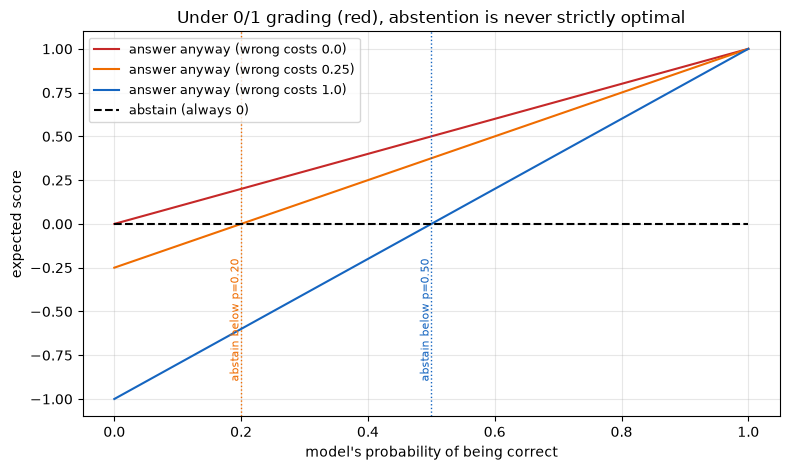

In [6]:
def expected_score(p_correct, wrong_penalty=0.0, answer=True):
    """Expected score of answering (with accuracy p) vs. abstaining.

    Scoring rule: +1 for a correct answer, -wrong_penalty for a wrong one,
    0 for abstaining.
    """
    if not answer:
        return np.zeros_like(p_correct)
    return p_correct * 1.0 - (1.0 - p_correct) * wrong_penalty


p = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(8, 4.8))
for penalty, color in [(0.0, "#c62828"), (0.25, "#ef6c00"), (1.0, "#1565c0")]:
    ax.plot(p, expected_score(p, penalty), color=color,
            label=f"answer anyway (wrong costs {penalty})")
    if penalty > 0:
        break_even = penalty / (1.0 + penalty)   # answer EV = p - penalty(1-p) = 0
        ax.axvline(break_even, color=color, ls=":", lw=1)
        ax.annotate(f"abstain below p={break_even:.2f}",
                    xy=(break_even, -0.9), fontsize=8, color=color,
                    rotation=90, va="bottom", ha="right")

ax.plot(p, np.zeros_like(p), "k--", lw=1.5, label="abstain (always 0)")
ax.set_xlabel("model's probability of being correct")
ax.set_ylabel("expected score")
ax.set_title("Under 0/1 grading (red), abstention is never strictly optimal")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig("figures/session4_incentive.png", dpi=120)
plt.show()

The red line is the standard benchmark rule, and it sits above the abstention line everywhere except at p = 0, where it merely ties. **A model optimized against that rule is being paid to guess at every level of ignorance.** Only when wrong answers are penalized (the orange and blue lines — the old SAT's guessing penalty, essentially) does abstention become the score-maximizing move below a threshold, and the threshold moves with the penalty.

The same arithmetic runs inside preference-based post-training. If a human rater, shown *"I don't know"* next to a confident, fluent, plausible answer, prefers the confident one — and raters routinely do, because it is more helpful-looking — then the reward model learns the red line. Session 6 measures one specific casualty of exactly this pressure; Session 7 shows the training machinery that applies it.

**This one is actionable.** Unlike 2a and 2b, the incentive argument points at a fixable thing: if you build an internal eval for your own use, grade abstention as *better than* a wrong answer. You will get a different model behavior for free, because you changed what you were paying for.

---

## Part 3 — Snowballing: how one token becomes a paragraph of fiction

The three arguments above explain why *some* output will be fabricated. They do not explain why the fabrication comes out as a confident, coherent, multi-sentence construction rather than as visible confusion. That is a separate mechanism, and it follows directly from what you saw in Session 1: generation is a **left-to-right commitment**, not a search over answers.

Zhang et al. (2023), *"How Language Model Hallucinations Can Snowball"*, isolated it: when a model commits to an early token that turns out to be wrong, every subsequent token is conditioned on that commitment. The model is not "lying" afterwards — it is doing exactly its job, which is to produce the most plausible continuation *of the text so far*, and the text so far contains the error. A coherent justification for a false claim is the locally correct next thing to write.

Their sharpest observation: the model often **can** recognize the error when asked about it separately. The knowledge was there; the commitment overrode it.

We will reproduce that with primality questions, because the ground truth is computable — the notebook checks the arithmetic itself rather than trusting a hand-written answer key.

In [7]:
def is_prime(n: int) -> bool:
    if n < 2:
        return False
    if n % 2 == 0:
        return n == 2
    f = 3
    while f * f <= n:
        if n % f == 0:
            return False
        f += 2
    return True


def smallest_factor(n: int) -> int:
    f = 2
    while f * f <= n:
        if n % f == 0:
            return f
        f += 1
    return n


# A mixed pool: genuine primes, and semiprimes built from two mid-sized
# primes (odd, no small factors, "prime-looking" to a model that is
# pattern-matching rather than dividing). Truth is computed, not asserted —
# that is the whole point of using arithmetic for this demo.
CANDIDATES = [7919, 9973, 10007, 8311, 9127,      # prime
              9991, 10403, 8051, 9409, 10001]     # composite

for n in CANDIDATES:
    f = smallest_factor(n)
    print(f"{n}: prime={is_prime(n)}"
          + ("" if is_prime(n) else f"  ({f} × {n // f})"))

7919: prime=True
9973: prime=True
10007: prime=True
8311: prime=True
9127: prime=True
9991: prime=False  (97 × 103)
10403: prime=False  (101 × 103)
8051: prime=False  (83 × 97)
9409: prime=False  (97 × 97)
10001: prime=False  (73 × 137)


Now we ask the model, and — instead of reading its generated text — we read the probability it assigns to each of the two possible openings. This is the Session 3 instrument: `sequence_logprob` scores a continuation we supply, in one forward pass, with no sampling noise at all.

In [8]:
def chat_prefix(user_msg: str, system_prompt: str | None = None) -> str:
    """The exact string the model sees before it starts its own turn.

    We need this as a *string* (not token ids) so we can append a forced
    opening to it later — that is how the causal intervention works.
    """
    messages = ([{"role": "system", "content": system_prompt}] if system_prompt else [])
    messages = messages + [{"role": "user", "content": user_msg}]
    return tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )


PRIME_QUESTION = ("Is {n} a prime number? Start your answer with Yes or No, "
                  "then explain your reasoning.")

rows = []
for n in CANDIDATES:
    ctx = chat_prefix(PRIME_QUESTION.format(n=n))
    yes = sequence_logprob(model, tokenizer, ctx, "Yes", warn_on_retokenization=False)
    no = sequence_logprob(model, tokenizer, ctx, "No", warn_on_retokenization=False)
    p_yes = np.exp(yes.total_logprob) / (np.exp(yes.total_logprob) + np.exp(no.total_logprob))
    truth = is_prime(n)
    model_says_prime = p_yes > 0.5
    rows.append({"n": n, "p_yes": p_yes, "truth": truth, "wrong": model_says_prime != truth})
    flag = "  <-- commits to the wrong answer" if rows[-1]["wrong"] else ""
    print(f"{n}: P(model opens with 'Yes') = {p_yes:6.1%}   truth: "
          f"{'prime' if truth else 'composite'}{flag}")

7919: P(model opens with 'Yes') =  37.8%   truth: prime  <-- commits to the wrong answer
9973: P(model opens with 'Yes') =  24.5%   truth: prime  <-- commits to the wrong answer
10007: P(model opens with 'Yes') =  53.1%   truth: prime
8311: P(model opens with 'Yes') =  24.5%   truth: prime  <-- commits to the wrong answer
9127: P(model opens with 'Yes') =  11.9%   truth: prime  <-- commits to the wrong answer
9991: P(model opens with 'Yes') =  26.9%   truth: composite
10403: P(model opens with 'Yes') =  20.2%   truth: composite
8051: P(model opens with 'Yes') =   5.3%   truth: composite
9409: P(model opens with 'Yes') =  11.9%   truth: composite
10001: P(model opens with 'Yes') =  40.7%   truth: composite


Note what this measurement *is*: not "the model got it wrong once," but the model's own probability of opening its turn with each of the two words. A value near 0.5 means the answer is a coin flip that the sampler will decide; a value near 0.05 means the commitment is made before a single word of reasoning exists.

**Read the whole column before reading any single row.** On Qwen2.5-1.5B-Instruct, `P(Yes)` sits below 0.5 for essentially *every* four- and five-digit number in the list — primes and composites alike. The model is not failing at trial division; it is not attempting trial division. It has a prior about what a number of this size "usually is" when someone asks, and that prior is what produces the opening word. The reasoning that follows is generated *after* the verdict, which is precisely the setup for what comes next.

So on this checkpoint the reliable errors are the **primes** — the cases where the blanket "No" is wrong. Let's take whichever case the model commits to most confidently in the wrong direction, and watch what it builds on top of it.

In [9]:
wrong_cases = [r for r in rows if r["wrong"]]
if not wrong_cases:
    print("No confident error found in the candidate list — your checkpoint is doing better "
          "than expected. Add more four- and five-digit primes and semiprimes to CANDIDATES "
          "and rerun; falling back to the most contested case.")
    case = max(rows, key=lambda r: abs(r["p_yes"] - 0.5))
else:
    case = max(wrong_cases, key=lambda r: abs(r["p_yes"] - 0.5))

N = case["n"]
FACTOR = smallest_factor(N)
print(f"Working case: {N}  (truth: {'prime' if case['truth'] else f'composite, {FACTOR} × {N // FACTOR}'})")
print(f"Model's P(opens with 'Yes'): {case['p_yes']:.1%}\n")

ctx = chat_prefix(PRIME_QUESTION.format(n=N))

set_all_seeds(0)
free_run = generate_with_topk_trace(
    model, tokenizer, prompt=ctx, max_new_tokens=140, k=5, temperature=0.0,
)
print("--- the model, left to its own devices (greedy) ---")
print(free_run.completed_text)

Working case: 9127  (truth: prime)
Model's P(opens with 'Yes'): 11.9%

--- the model, left to its own devices (greedy) ---
No, 9127 is not a prime number. 

To determine this, we can check for divisibility by prime numbers up to the square root of 9127. The square root of 9127 is approximately 95.5, so we only need to check for divisibility by prime numbers less than or equal to 95.

- 9127 is odd, so it is not divisible by 2.
- The sum of the digits of 9127 is 9 + 1 + 2 + 7 = 19, which is not divisible by 3, so 9127 is not


Read the first few steps of the trace to see the commitment happen as a single event.

In [10]:
print(free_run.as_table(max_alt=2).split("\n")[0])
for s in free_run.steps[:6]:
    alts = "  ".join(f"{t!r}:{p:.3f}" for t, p in zip(s.topk_strs[1:3], s.topk_probs[1:3]))
    print(f"{s.step:4d} | {s.picked_str!r:>14} {s.picked_prob:6.3f} | {alts}")

step | picked                 p       | alt#2                 p | alt#3                 p
   0 |           'No'  0.838 | 'Yes':0.113  '**':0.025
   1 |            ','  0.762 | '.\n\n':0.117  '.\n':0.071
   2 |            ' '  0.998 | ' the':0.001  ' not':0.001
   3 |            '9'  1.000 | '1':0.000  '2':0.000
   4 |            '1'  0.997 | ',':0.003  '9':0.000
   5 |            '2'  1.000 | ',':0.000  '3':0.000


**The commitment token is step 0.** Everything after it is elaboration — and the elaboration is typically *good writing*: it cites the right concepts (divisibility, square roots, trial division), it has the right shape, and it reaches a conclusion. It is also a justification of something false, often including a confidently-stated "I checked all factors up to √n" that never happened, or a specific divisor that does not divide anything.

### The intervention: change one token, change the answer

We now do the thing you cannot do through a chat interface. The chat prefix is just a string; the model's turn is whatever comes after it. So we append the *correct* opening word ourselves and let the model continue from there. This is teacher forcing used causally — prefilling the assistant turn.

In [11]:
correct_opener = "No" if not case["truth"] else "Yes"
forced_ctx = ctx + correct_opener

set_all_seeds(0)
forced_run = generate_with_topk_trace(
    model, tokenizer, prompt=forced_ctx, max_new_tokens=140, k=5, temperature=0.0,
)
print(f"--- the same model, with its first token forced to {correct_opener!r} ---")
print(correct_opener + forced_run.completed_text)

--- the same model, with its first token forced to 'Yes' ---
Yes, 9127 is a prime number. 

To explain my reasoning, I will use the definition of a prime number: a prime number is a natural number greater than 1 that has no positive divisors other than 1 and itself. 

To check if 9127 is a prime number, we need to see if it has any divisors other than 1 and 9127. We can do this by checking if it is divisible by any prime numbers less than or equal to the square root of 9127. The square root of 9127 is approximately 95.5, so we only need to check for divis


**What just happened, and what didn't.** One token changed by hand; the entire subsequent paragraph reorganized itself around it. The model did not "become better at arithmetic" — it was never doing arithmetic. It was writing a plausible continuation, and we changed what it was continuing.

Be honest about the limits of the fix: forcing the correct opener removes the *commitment pressure*, but the justification that follows may still be wrong in its details — a made-up factor, a bogus divisibility claim, a trial division that never happened. Read the forced run's reasoning against the arithmetic printed above; on a 1.5B model it is frequently wrong even when the verdict is now right. That combination, right answer with fabricated reasoning, is its own well-documented problem and a good argument for never treating the model's explanation as evidence for its conclusion.

This is nonetheless the seed of Session 7: a behavior that post-training made unreachable can sometimes be restored by intervening at a single early token, with no retraining at all.

### Measuring the trap closing

The intervention shows the snowball qualitatively. Now measure it. Take the fabricated answer and, at each point along it, ask the model how willing it would be to write the *truthful* correction — and, as a control, the *affirming* continuation that stays on the fabricated path. If the snowball is real, the two lines should cross and then diverge.

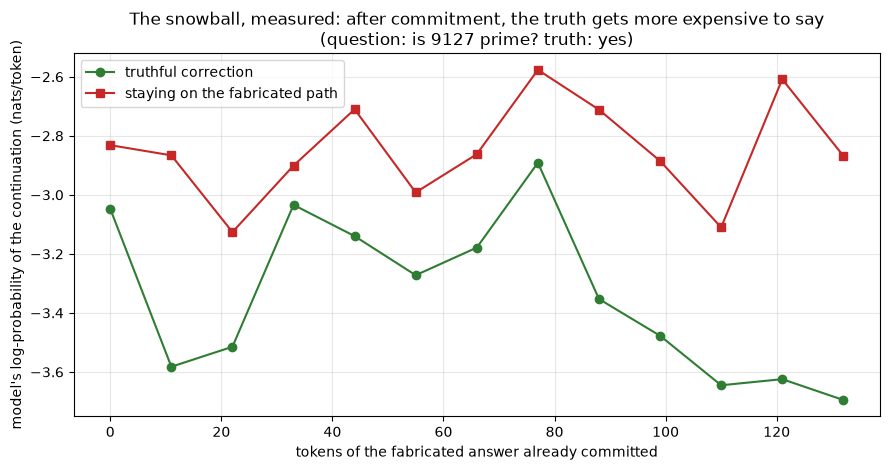

In [12]:
truth_word = "is" if case["truth"] else "is not"
CORRECTION = (f"\n\nActually, that reasoning is wrong: {N} {truth_word} a prime number.")
AFFIRMATION = (f"\n\nTo confirm, the reasoning above is correct: {N} "
               f"{'is' if not case['truth'] else 'is not'} a prime number.")

wrong_text = free_run.completed_text
wrong_ids = tokenizer(wrong_text, add_special_tokens=False).input_ids
cut_points = list(range(0, len(wrong_ids) + 1, max(1, len(wrong_ids) // 12)))

corr_curve, aff_curve = [], []
for j in cut_points:
    prefix = ctx + tokenizer.decode(wrong_ids[:j])
    corr_curve.append(sequence_logprob(model, tokenizer, prefix, CORRECTION,
                                       warn_on_retokenization=False).mean_logprob)
    aff_curve.append(sequence_logprob(model, tokenizer, prefix, AFFIRMATION,
                                      warn_on_retokenization=False).mean_logprob)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(cut_points, corr_curve, "-o", color="#2e7d32", label="truthful correction")
ax.plot(cut_points, aff_curve, "-s", color="#c62828", label="staying on the fabricated path")
ax.set_xlabel("tokens of the fabricated answer already committed")
ax.set_ylabel("model's log-probability of the continuation (nats/token)")
ax.set_title(f"The snowball, measured: after commitment, the truth gets more expensive to say\n"
             f"(question: is {N} prime? truth: {'yes' if case['truth'] else 'no'})")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("figures/session4_snowball_curve.png", dpi=120)
plt.show()

**How to read it.** Both curves are per-token log-probabilities, so they are comparable despite the two strings having different lengths (this is why `mean_logprob` and not `total_logprob` — a longer sentence is automatically less probable, which would be a fact about length, not about the model's opinion).

The expected pattern: early in the answer the two are close — the model is not yet committed and could still go either way. As the fabricated answer accumulates, the affirming continuation gets *cheaper* and the correction gets *more expensive*. The model is not becoming more wrong; it is becoming more **consistent with itself**, which is the same thing from the inside and a completely different thing from the outside.

Two honest caveats. First, part of any downward drift is generic: longer contexts change fluency for all continuations, which is why we plot a control curve rather than the correction alone — it is the *gap* that carries the signal. Second, on a 1.5B model these curves are noisy; treat a small gap as no result rather than a weak one.

### Does the model know better?

Zhang et al.'s follow-up question. Ask, in a *fresh* conversation with no committed prefix, a question whose answer the fabricated path implicitly denied.

In [13]:
if case["truth"]:   # a prime the model called composite
    checks = [
        (f"List all positive divisors of {N}. Reply with the numbers only.",
         f"1 and {N} — nothing else, because {N} is prime."),
        (f"What is the remainder when {N} is divided by 7? Answer with the number only.",
         str(N % 7)),
    ]
else:               # a composite the model called prime
    checks = [
        (f"Is {N} divisible by {FACTOR}? Answer Yes or No only.", "Yes"),
        (f"What is {FACTOR} × {N // FACTOR}? Answer with the number only.", str(N)),
    ]

for q, truth in checks:
    out = sample_completions(model, tokenizer, q, n=1, temperature=0.0,
                             max_new_tokens=24, apply_chat_template=True)[0]
    print(f"Q: {q}\nA: {' '.join(out.split())[:140]}\n   (ground truth: {truth})\n")

Q: List all positive divisors of 9127. Reply with the numbers only.
A: 1, 13, 683, 9127
   (ground truth: 1 and 9127 — nothing else, because 9127 is prime.)

Q: What is the remainder when 9127 is divided by 7? Answer with the number only.
A: 5
   (ground truth: 6)



At 1.5B, this check often fails too — the model may get the multiplication wrong, which means we cannot cleanly claim "the knowledge was there." At 7B and above it usually succeeds, and the dissociation is stark: asked directly, the model divides correctly; asked inside a turn it has already committed, it maintains the fabrication. Report what you actually see, not what the story wants.

### The picture

The figure below is an *illustration*, not a measurement: a cartoon of the mechanism you just measured, in the style Session 5 will make explicit. Two regions of "where answers end up" — one correct, one fabricated — and a trajectory that lands in the wrong one because of a choice made in the first step.

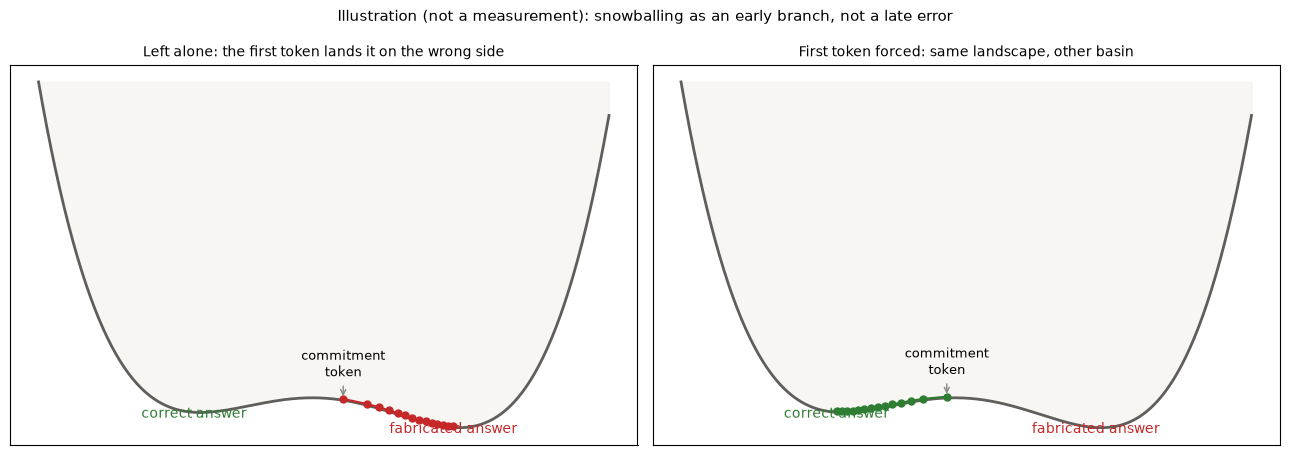

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# A cartoon landscape: two wells, "correct" and "fabricated"
xs = np.linspace(-2.2, 2.2, 400)


def landscape(x):
    return (x ** 2 - 1.0) ** 2 - 0.35 * x


for ax, (title, start, drift) in zip(
    axes,
    [("Left alone: the first token lands it on the wrong side", 0.15, +1),
     ("First token forced: same landscape, other basin", -0.15, -1)],
):
    ax.plot(xs, landscape(xs), color="#5f5e5a", lw=2)
    ax.fill_between(xs, landscape(xs), landscape(xs).max(), color="#f1efe8", alpha=0.5)

    # a trajectory: starts near the ridge, slides into one well
    traj_x = start + drift * np.linspace(0, 1, 14) ** 0.6 * (1.0 - abs(start))
    traj_x = np.clip(traj_x, -1.6, 1.6)
    ax.plot(traj_x, landscape(traj_x) + 0.06, "-o", color="#c62828" if drift > 0 else "#2e7d32",
            ms=5, lw=1.5)
    ax.annotate("commitment\ntoken", xy=(start, landscape(start) + 0.06),
                xytext=(start, landscape(start) + 1.1), fontsize=9, ha="center",
                arrowprops=dict(arrowstyle="->", color="#888780"))

    ax.text(-1.0, landscape(-1.0) - 0.25, "correct answer", ha="center", fontsize=10, color="#2e7d32")
    ax.text(1.0, landscape(1.0) - 0.25, "fabricated answer", ha="center", fontsize=10, color="#c62828")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Illustration (not a measurement): snowballing as an early branch, not a late error",
             fontsize=11)
plt.tight_layout()
plt.savefig("figures/session4_snowball_illustration.png", dpi=120)
plt.show()

The hygiene note that Session 5 will make properly: this picture is a *metaphor with a specific job*. There is no energy function in a transformer, no two-dimensional state, no marble. What there is: a measurable tendency for outputs to concentrate, and a measurable asymmetry in how easily generation moves between those concentrations. The cartoon is a way of holding that in your head — and the next session is about how much of it survives contact with measurement.

---

## So what, for a working scientist

- **"Hallucination" is not one phenomenon, and the fix depends on which one you have.** If the model contradicts a document you supplied (intrinsic), the levers are retrieval quality, context length, and position of the key passage — prompt engineering genuinely helps. If it invents a citation that never existed (extrinsic), no prompt discipline will help, because the prompt was never the problem: you need an external check. **Practical implication:** for literature work, "give the model the paper" and "ask the model about the paper" are two different risk profiles, and only the first is prompt-fixable.

- **The lower bound is about a population, not about your sentence.** Kalai & Vempala tell you a calibrated model must be wrong at some rate on one-off facts. They do not tell you whether *this* answer is one. Anyone selling you a hallucination-free model is either restricting the domain (fine, and useful) or miscalibrating deliberately toward refusal (also fine, also a trade-off) — but not solving it. **Practical implication:** ask a vendor which of the two they did. The answer is informative and they rarely volunteer it.

- **Grading rules propagate into behavior.** The 0/1 line in Part 2c is the reason confident guessing is the house style of the whole field. It applies to your own evals too. **Practical implication:** if you build an internal benchmark for model selection, score "I don't know" above a wrong answer — otherwise your benchmark will faithfully select the model that guesses best, which is probably not what you wanted.

- **Commitment happens early, and you can sometimes see it.** The snowball curve says a wrong answer becomes progressively more expensive to retract. Through an API you cannot prefill the assistant turn on every provider, but you *can* exploit the same mechanism in reverse. **Practical implication:** ask for the verdict *after* the reasoning, not before ("work through it, then state your conclusion"), and never accept a self-justification generated after a committed answer as evidence for that answer — it is, mechanically, the part of the output most constrained to agree with it.

---

## Exercises

**1. Break the faithful case.** Part 1a's intrinsic demo usually passes. Make it fail: (a) pad the passage with 500+ tokens of unrelated filler before the key sentence; (b) make the claim more strongly counter-prior; (c) ask a question requiring two sentences of the passage to be combined. For each variant, run 20 samples and report the contradiction rate. Which manipulation moves it most?

**2. Greedy vs. sampled fabrication.** Does the model hallucinate more at T=0 or at T=1.0? Take 10 questions about non-existent entities, 20 samples each at both temperatures, and classify each output as *specific claim* vs. *hedge/refusal* with a simple keyword rule. Report the two rates with a bootstrap confidence interval over questions. **Design note:** with 10 questions your interval will be wide — this exercise is calibrated to let you *observe* the effect and the uncertainty, not to conclude anything. State explicitly what n you would need for a claim, and why the answer is not intuitive in either direction (higher temperature adds diversity, but greedy decoding concentrates on the single most "typical-looking" answer, which is exactly the fabrication mode).

**3. Where is the commitment token?** Run the Part 3 primality probe on all eight candidates. For each, record P(opens with "Yes"). Then find a question type where the commitment happens *later* than step 0 — e.g. one where the model opens with a preamble ("Let me check...") before committing. Does the snowball curve look different when commitment is delayed? This is the mechanism behind chain-of-thought prompting, measured.

**4. Your own incentive audit.** Take any benchmark or eval you actually use (or a rubric from your own field). Write down its scoring rule explicitly. Under that rule, plot the expected score for "answer always" vs. "abstain below threshold p", as in Part 2c. At what accuracy does abstention pay? If the answer is "never," you have found a benchmark that pays for fabrication.

**5. (Harder) The correction gap across model sizes.** If you have access to a second, larger model (Qwen2.5-3B or 7B-Instruct), rerun the snowball curve on the same question. Does the gap between the correction and affirmation curves open earlier, later, or not at all? Larger models are known to be better at self-correction *when asked separately* — is that visible in the committed-prefix measurement?

## What you just did

- Separated intrinsic from extrinsic hallucination, and both from the things routinely mislabeled as hallucination (abstention, hedging, refusal, staleness).
- Attached three distinct inevitability arguments to their correct sources — computability (Xu et al. 2024), calibration and the monofact/Good–Turing bound (Kalai & Vempala 2024), and grading incentives (OpenAI 2025) — and computed the arithmetic behind the last two yourself.
- Found a model's commitment token by reading its own probability for each opening word, with no sampling involved.
- Performed the workshop's first causal intervention: prefilled one token into the assistant turn and watched an entire fabricated paragraph reorganize into a different answer.
- Measured the snowball closing — the per-token cost of retracting a claim, rising as the claim accumulates support, against a control continuation.

## Forward hook

So the model must produce *something*, and once it starts it is committed. That leaves the real question: what shapes *what* it produces? **Session 5** is a gallery of places models reliably end up regardless of what you asked — random numbers that aren't random, paraphrases that converge to the same bland sentence, loops that never end — and the vocabulary (basin, depth, width) for talking about them without overclaiming.